# 06 · Sequence data and regularisation

**Owner:** Kushal Tyagi · Phase 2 (deep learning)

**Phase 2: deep learning.** Phase 1 showed that engineered degradation features with XGBoost reach a test RMSE of **10.75 cycles**. Its error analysis (notebook 05) also showed where fixed-window features fall short:

- **fast-degrading engines** were predicted about 10 cycles too late,
- error peaked at the **onset of degradation** (RUL 70–110),
- **short histories** (fewer than 60 observed cycles) were harder.

All three depend on the shape and timing of the whole recent trajectory, which a hand-chosen 10- or 30-cycle summary captures poorly. Phase 2 tests whether models that **learn directly from the sensor sequence** do better, and whether combining both views in a **hybrid** model does better still.

| # | Notebook | Rubric focus |
|---|---|---|
| **06** | **Sequence data and regularisation** | DL dataset, leakage control, regularisation plan |
| 07 | Sequence models: LSTM, TCN, Transformer | architecture logic, theory, CV comparison |
| 08 | Hybrid feature-fusion model | hybrid innovation and its justification |
| 09 | Ablation studies | what each design choice contributes |
| 10 | Test evaluation and validation | official test set, seeds, significance, stages |

This notebook builds the inputs for the networks and fixes the rules that keep the evaluation honest.

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import USEFUL_SENSORS, SENSOR_INFO, RUL_CAP
from src.data import load_cmapss, add_train_rul, add_test_rul
from src.sequences import SequenceBuilder, make_windows
from src.models import engine_folds
from src.plotting import set_style, save, BLUE, ORANGE, AQUA, GREY, INK, SEQUENTIAL

set_style()
train, test, rul = load_cmapss("FD001")
train, test = add_train_rul(train), add_test_rul(test, rul)

## 1. From rows to windows

A sequence model needs, for every prediction, a slice of the engine's recent history rather than one row. For the cycle *t* of engine *i* we take the **window** of the last *W* cycles,

$$X_{i,t} = \big[\,z_{i,t-W+1},\; \dots,\; z_{i,t}\,\big] \in \mathbb{R}^{W \times 14},$$

where $z$ are the 14 sensors after the same z-score normalisation as Phase 1 (fitted on training engines only). The target is the capped RUL at cycle *t*, exactly as in Phase 1, so the two phases predict the same quantity. With a stride of one cycle, every row of the data becomes one window, so the networks are trained and evaluated on the **same cycles** as the Phase 1 models.

In [2]:
W = 30
sb = SequenceBuilder(window=W).fit(train)
data = sb.transform(train)
print(f"windows          : {data['x'].shape}   (rows, time steps, 14 sensors + mask)")
print(f"engineered feats : {data['f'].shape}   (used only by the hybrid model)")
print(f"targets          : {data['y'].shape}")

windows          : (20631, 30, 15)   (rows, time steps, 14 sensors + mask)
engineered feats : (20631, 88)   (used only by the hybrid model)
targets          : (20631,)


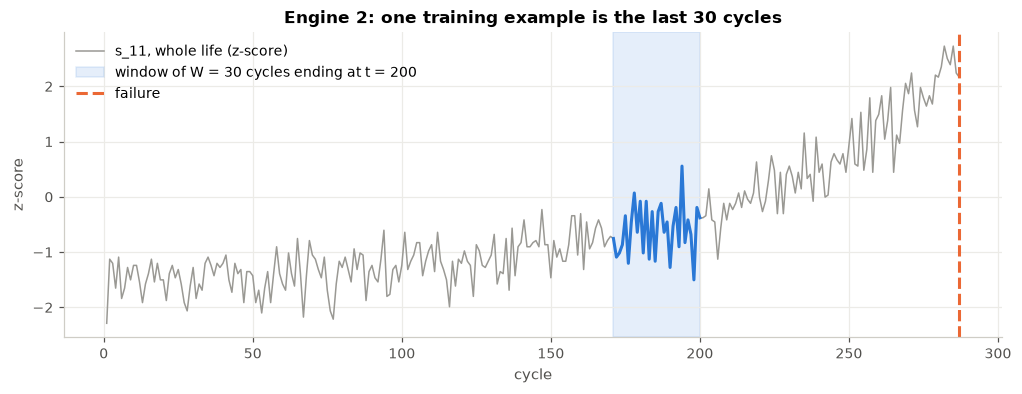

In [3]:
unit, t = 2, 200
e = train[train["unit"] == unit].sort_values("cycle")
z = pd.Series(data["x"][(data["unit"] == unit) & (data["cycle"] == t)][0, :, USEFUL_SENSORS.index("s_11")])

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(e["cycle"], (e["s_11"] - train["s_11"].mean()) / train["s_11"].std(), color=GREY, lw=1, label="s_11, whole life (z-score)")
ax.axvspan(t - W + 1, t, color=BLUE, alpha=0.12, label=f"window of W = {W} cycles ending at t = {t}")
ax.plot(np.arange(t - W + 1, t + 1), z, color=BLUE, lw=2)
ax.axvline(e["cycle"].max(), color=ORANGE, ls="--", label="failure")
ax.set(title=f"Engine {unit}: one training example is the last {W} cycles", xlabel="cycle", ylabel="z-score")
ax.legend(loc="upper left")
save(fig, "06_window_example")
plt.show()

## 2. Short histories: padding and a mask channel

Early in an engine's life fewer than *W* cycles exist. Instead of throwing these cycles away (as many papers do), we **left-pad the window with the engine's own first reading** and add a 15th input channel, the **mask**, which is 1 for real cycles and 0 for padding. This matters because:

- Phase 1 found short histories to be a weak spot, so they should stay in training and evaluation;
- some test engines have only 31 observed cycles, so with longer windows the model must handle padding at test time anyway;
- without the mask, a padded window (constant values) would look like a perfectly flat, healthy engine.

The Transformer uses the mask to exclude padded steps from attention; the LSTM and TCN receive it as an input feature.

In [4]:
toy = make_windows(np.arange(1, 7, dtype=float).reshape(-1, 1), np.ones(6), window=4)
pd.DataFrame({"cycle": range(1, 7),
              "window (sensor)": [list(map(int, w)) for w in toy[:, :, 0]],
              "mask": [list(map(int, w)) for w in toy[:, :, 1]]}).set_index("cycle")

,window (sensor),mask
cycle,,
1,"[1, 1, 1, 1]","[0, 0, 0, 1]"
2,"[1, 1, 1, 2]","[0, 0, 1, 1]"
3,"[1, 1, 2, 3]","[0, 1, 1, 1]"
4,"[1, 2, 3, 4]","[1, 1, 1, 1]"
5,"[2, 3, 4, 5]","[1, 1, 1, 1]"
6,"[3, 4, 5, 6]","[1, 1, 1, 1]"


In [5]:
obs = test.groupby("unit")["cycle"].max()
pad = pd.DataFrame({"window W": [30, 50, 80],
                    "test engines shorter than W": [(obs < w).sum() for w in (30, 50, 80)],
                    "test cycles with padding (%)": [100 * (test["cycle"] < w).mean() for w in (30, 50, 80)],
                    "train cycles with padding (%)": [100 * (train["cycle"] < w).mean() for w in (30, 50, 80)]})
pad.round(1).set_index("window W")

,test engines shorter than W,test cycles with padding (%),train cycles with padding (%)
window W,,,
30,0,22.1,14.1
50,7,37.0,23.8
80,23,56.8,38.3


With W = 30, every test engine has at least 31 observed cycles, so all **last-cycle** predictions use complete windows. Still, 22% of all test cycles and 14% of training cycles are early cycles with a partly padded window, and they stay in training and evaluation. Longer windows quickly need more padding: at W = 80, 23 test engines are shorter than the window and 57% of test cycles are padded. This trade-off is tested in the window-length ablation (notebook 09).

## 3. What the network sees

Each window is a small image: 14 sensors × W time steps. Below, a window from early life and one from just before failure for the same engine. Near failure the sensors have drifted in a consistent pattern (rows that rise and rows that fall), which a convolution or recurrent cell can learn to recognise as a shape, rather than as 88 separately computed numbers.

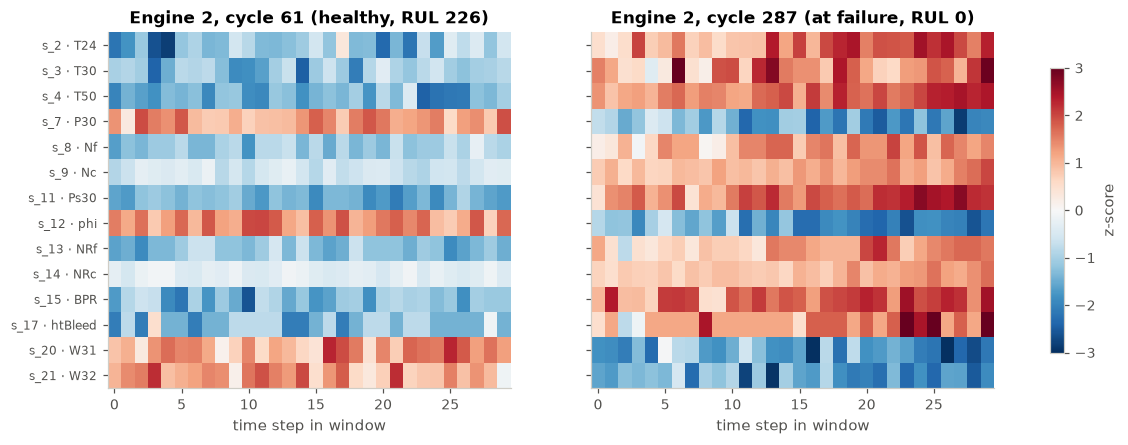

In [6]:
unit = 2
rows = np.flatnonzero(data["unit"] == unit)
early, late = rows[60], rows[-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, r, title in [(axes[0], early, "healthy"), (axes[1], late, "at failure")]:
    im = ax.imshow(data["x"][r, :, :-1].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set(title=f"Engine {unit}, cycle {data['cycle'][r]} ({title}, RUL {int(data['y'][r])})", xlabel="time step in window")
    ax.grid(False)
axes[0].set_yticks(range(14), [f"{s} · {SENSOR_INFO[s][0]}" for s in USEFUL_SENSORS], fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.8, label="z-score")
save(fig, "06_window_heatmaps")
plt.show()

## 4. Leakage checks

The same three rules as Phase 1 apply, and are tested automatically in `tests/test_sequences.py`:

1. **No window crosses an engine boundary.** Every window contains only its own engine's cycles.
2. **Windows are causal.** Recomputing all windows after deleting every engine's future gives identical values for the remaining cycles.
3. **Fitted transforms see training engines only.** Normalisation statistics and the engineered features (for the hybrid) are refitted inside each CV fold.

In [7]:
# Rule 1: windows never mix engines -- rebuild each engine's windows from that engine ALONE
mixed = 0
for u in np.unique(data["unit"]):
    own = sb.scaler_.transform(train[train["unit"] == u]).to_numpy()
    alone = make_windows(own, np.full(len(own), u), W)
    mixed += int(not np.allclose(alone, data["x"][data["unit"] == u]))
print("engines whose windows differ from windows built from that engine alone:", mixed)

# Rule 2: causality -- delete each engine's future and rebuild
cut = sb.transform(train[train["cycle"] <= 80])
keep = np.isin(data["cycle"], cut["cycle"]) & (data["cycle"] <= 80)
diff = np.abs(data["x"][keep] - cut["x"]).max()
print(f"max difference after deleting the future: {diff:.2e}")
assert mixed == 0 and diff < 1e-6

engines whose windows differ from windows built from that engine alone: 0
max difference after deleting the future: 0.00e+00


## 5. Training, validation and test splits

| Set | Engines | Used for |
|---|---|---|
| CV training engines | 72 per fold | fitting the network weights |
| Inner validation engines | 8 per fold (10% of training) | **early stopping** and the learning-rate schedule |
| CV evaluation engines | 20 per fold | the CV score (never seen during training or early stopping) |
| Official test engines | 100 | used **once**, in notebook 10 |

The 5 folds are **identical to Phase 1** (same engine ids per fold), so CV scores of the networks and of XGBoost are directly comparable. Early stopping uses separate engines from the evaluation fold; otherwise the CV score would be optimistic.

In [8]:
folds = engine_folds(train["unit"])
pd.DataFrame({"fold": range(1, 6), "evaluation engines": [len(f) for f in folds],
              "first engines in fold": [", ".join(map(str, f[:6])) + ", ..." for f in folds]}).set_index("fold")

,evaluation engines,first engines in fold
fold,,
1,20,"3, 5, 19, 22, 25, 26, ..."
2,20,"1, 8, 11, 18, 27, 29, ..."
3,20,"2, 4, 6, 21, 24, 33, ..."
4,20,"10, 16, 17, 31, 32, 35, ..."
5,20,"7, 9, 12, 13, 14, 15, ..."


## 6. Regularisation plan

FD001 has only 100 training engines. The windows overlap heavily (consecutive windows share W−1 cycles), so the effective amount of independent data is far smaller than the 20,631 windows suggest, and a network with tens of thousands of weights can memorise individual engines. We therefore combine several regularisers; notebook 09 measures what each contributes.

| Technique | What it does | Setting |
|---|---|---|
| **Dropout** (Srivastava et al., 2014) | randomly zeroes activations during training, so no unit can rely on one specific co-adapted partner; at test time it acts like averaging many thinned networks | p = 0.2 (0.1 in the Transformer) |
| **Weight decay** (L2) | adds λ‖w‖² to the loss, shrinking weights towards 0, the same idea as Ridge regression | λ = 1e-4 (AdamW) |
| **Early stopping** | stops when the error on the inner-validation engines has not improved for 8 epochs and restores the best weights | patience 8, max 60 epochs |
| **Learning-rate schedule** | halves the learning rate when validation error plateaus, so training settles into a minimum instead of oscillating | factor 0.5, patience 3 |
| **Gradient clipping** | caps the gradient norm, protecting the LSTM from exploding gradients | max norm 1.0 |
| **Input noise** (augmentation) | adds Gaussian noise to the sensor inputs during training (tested as an ablation) | σ = 0.05 z-units |
| **Capped target** | removes the unpredictable healthy-phase variation from the target (Phase 1) | cap 125 |

The target is divided by 125 so it lies in [0, 1], which keeps the output layer and the loss on a well-conditioned scale.

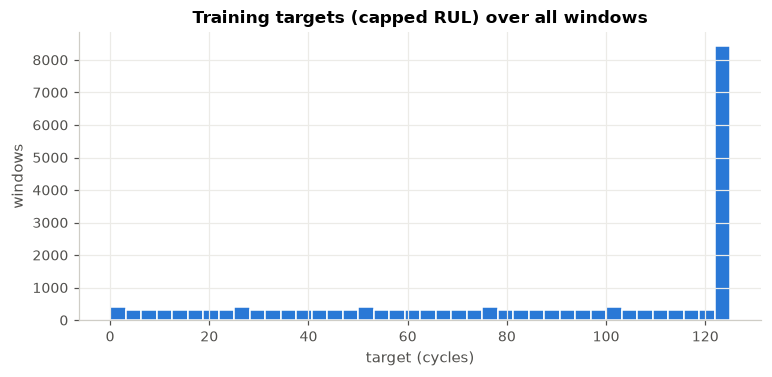

share of windows at the cap (healthy phase): 39.4%


In [9]:
y = np.minimum(data["y"], RUL_CAP)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(y, bins=40, color=BLUE, edgecolor="white")
ax.set(title="Training targets (capped RUL) over all windows", xlabel="target (cycles)", ylabel="windows")
save(fig, "06_target_distribution")
plt.show()
print(f"share of windows at the cap (healthy phase): {(y == RUL_CAP).mean():.1%}")

## Summary

- Every cycle becomes a 30 × 15 window (14 normalised sensors + mask) built only from that engine's past: **20,631 training windows**, the same rows Phase 1 used.
- Short histories are kept, padded with the engine's first reading and marked by a mask channel.
- Both leakage checks pass: no window crosses an engine boundary, and deleting the future changes nothing.
- The CV folds are identical to Phase 1; early stopping uses separate inner-validation engines.
- Regularisation: dropout, weight decay, early stopping, a learning-rate schedule and gradient clipping, plus input noise as an option. About 39% of windows sit at the cap (healthy phase), so the target is far from uniform, another reason to monitor validation error closely.